<a href="https://colab.research.google.com/github/sreejarepo/LLM_project1/blob/main/PartB_WGAN_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 2 – Part B: WGAN and WGAN-GP (CIFAR-10)

**Course:** AIML ZG533 Unsupervised Deep Learning (S1-26)  |  **Dataset:** CIFAR-10, pixels normalised to [0,1]

We train a Wasserstein GAN with **weight clipping** (WGAN) and a Wasserstein GAN with **gradient penalty** (WGAN-GP) using the *same* generator and critic architecture, generate random samples and report FID (10 000 samples vs. the 10 000 test images). FID is also tracked during training to show convergence.

**Model input scaling:** images are in [0,1] (as required); inside the networks they are mapped to [-1,1] (`2x-1`) to match the generator's `tanh` output, and generated images are mapped back to [0,1] for every metric/plot.

## 0. Setup, BITS lab GPU evidence and helpers

In [1]:
import os, sys, time, json, math, subprocess
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
from scipy import linalg

# SMOKE=1 is only used to test the code quickly on tiny synthetic data. Leave it unset for the real run.
SMOKE = os.environ.get("SMOKE", "0") == "1"
SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = os.environ.get("OUT_DIR", "outputs"); os.makedirs(OUT, exist_ok=True)

print("PyTorch", torch.__version__, "| device:", device, "| SMOKE:", SMOKE)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    try:
        print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)   # screenshot this for the infra proof
    except Exception as e:
        print("nvidia-smi not available:", e)
if not SMOKE:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pytorch-fid"], check=False)

PyTorch 2.14.1+cpu | device: cpu | SMOKE: False


In [2]:
# ---------------- data (CIFAR-10, pixels normalised to [0,1]) ----------------
def load_cifar10():
    if SMOKE:
        g = torch.Generator().manual_seed(0)
        base = torch.rand(768, 3, 8, 8, generator=g)
        x = F.interpolate(base, size=32, mode="bilinear", align_corners=False)
        return x[:512].contiguous(), x[512:].contiguous()
    tr = torchvision.datasets.CIFAR10("data", train=True, download=True)
    te = torchvision.datasets.CIFAR10("data", train=False, download=True)
    f = lambda d: torch.from_numpy(d.data).permute(0, 3, 1, 2).float().div(255.0).contiguous()
    return f(tr), f(te)

def batches(x, bs, shuffle=True, drop_last=True):
    n = x.shape[0]
    idx = torch.randperm(n) if shuffle else torch.arange(n)
    end = n - bs + 1 if drop_last else n
    for i in range(0, max(end, 1), bs):
        yield x[idx[i:i + bs]].to(device)

def psnr(x, y):
    """Mean per-image PSNR in dB for images in [0,1] (MAX = 1)."""
    mse = ((x - y) ** 2).flatten(1).mean(1).clamp_min(1e-10)
    return (10 * torch.log10(1.0 / mse)).mean().item()

def count_params(m):
    return sum(p.numel() for p in m.parameters())

def sync():
    if device.type == "cuda": torch.cuda.synchronize()

def save_grid(imgs, path, nrow=10):
    torchvision.utils.save_image(imgs[:nrow * nrow].float().cpu(), path, nrow=nrow, padding=1)

def show_grid(imgs, title="", nrow=10, figsize=(7, 7)):
    g = torchvision.utils.make_grid(imgs[:nrow * nrow].float().cpu(), nrow=nrow, padding=1)
    plt.figure(figsize=figsize); plt.imshow(g.permute(1, 2, 0).clamp(0, 1).numpy()); plt.axis("off"); plt.title(title); plt.show()

# ---------------- FID ----------------
FID_RES = 96 if SMOKE else 299

def build_feature_extractor():
    if not SMOKE:
        try:
            from pytorch_fid.inception import InceptionV3
            net = InceptionV3([InceptionV3.BLOCK_INDEX_BY_DIM[2048]]).to(device).eval()
            def feat(x):   # x in [0,1]; the network resizes to 299x299 and normalises internally
                return net(x)[0].squeeze(-1).squeeze(-1)
            return feat, "pytorch-fid Inception (standard FID weights, 2048-d pool features)"
        except Exception as e:
            print("pytorch-fid unavailable, falling back to torchvision Inception:", e)
    if SMOKE:
        net = torchvision.models.inception_v3(weights=None, aux_logits=False, init_weights=True)
    else:
        net = torchvision.models.inception_v3(weights=torchvision.models.Inception_V3_Weights.IMAGENET1K_V1)
    net.fc = nn.Identity(); net = net.to(device).eval()
    mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
    def feat(x):
        x = F.interpolate(x, size=(FID_RES, FID_RES), mode="bilinear", align_corners=False)
        f = net((x - mean) / std)
        return f[:, :64] if SMOKE else f      # smoke test: 64-d features keep sqrtm instant
    return feat, ("random-init Inception (SMOKE test only)" if SMOKE else "torchvision Inception-v3 (ImageNet weights)")

FEAT, FID_NAME = build_feature_extractor()
print("FID feature extractor:", FID_NAME)

@torch.no_grad()
def feats(imgs, bs=250):
    out = []
    for i in range(0, len(imgs), bs):
        out.append(FEAT(imgs[i:i + bs].to(device).float().clamp(0, 1)).cpu().double())
    return torch.cat(out).numpy()

def feat_stats(f):
    return f.mean(0), np.cov(f, rowvar=False)

def frechet(m1, s1, m2, s2, eps=1e-6):
    d = m1 - m2
    covmean = linalg.sqrtm(s1.dot(s2))
    if not np.isfinite(covmean).all():
        off = np.eye(s1.shape[0]) * eps
        covmean = linalg.sqrtm((s1 + off).dot(s2 + off))
    if np.iscomplexobj(covmean): covmean = covmean.real
    return float(d.dot(d) + np.trace(s1) + np.trace(s2) - 2 * np.trace(covmean))

def fid_score(gen_imgs):
    """FID between generated images (N,3,32,32 in [0,1]) and the real CIFAR-10 test images."""
    m, s = feat_stats(feats(gen_imgs))
    return frechet(m, s, REAL_M, REAL_S)

Downloading: "https://github.com/mseitzer/pytorch-fid/releases/download/fid_weights/pt_inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/pt_inception-2015-12-05-6726825d.pth


100%|██████████| 91.2M/91.2M [00:00<00:00, 247MB/s]


FID feature extractor: pytorch-fid Inception (standard FID weights, 2048-d pool features)


### Data

100%|██████████| 170M/170M [01:04<00:00, 2.66MB/s]


train (50000, 3, 32, 32) test (10000, 3, 32, 32) | range 0.0 1.0


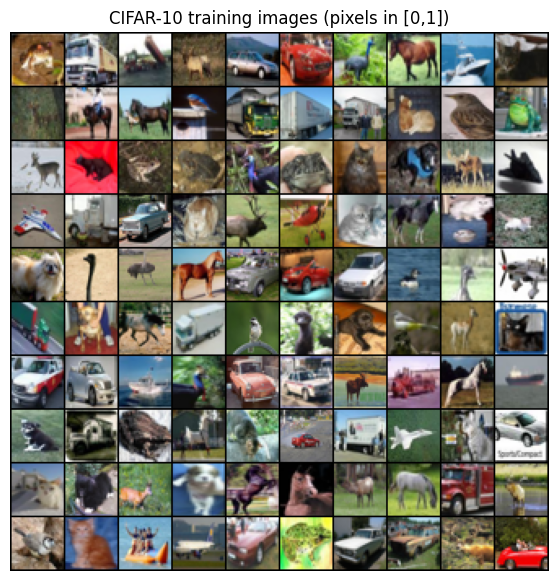

In [3]:
xtr, xte = load_cifar10()
print("train", tuple(xtr.shape), "test", tuple(xte.shape), "| range", float(xtr.min()), float(xtr.max()))
N_FID = min(10000, len(xte))            # number of generated images used for every reported FID
REAL_M, REAL_S = feat_stats(feats(xte[:N_FID]))
show_grid(xtr[:100], "CIFAR-10 training images (pixels in [0,1])")

## Method

The Wasserstein-1 distance (Kantorovich–Rubinstein duality) is
$$W(P_r,P_g)=\sup_{\lVert f\rVert_L\le1}\ \mathbb E_{x\sim P_r}[f(x)]-\mathbb E_{\tilde x\sim P_g}[f(\tilde x)],$$
where the supremum is over 1-Lipschitz functions, approximated by a **critic** $D$ (no sigmoid, no log). The critic maximises $D(x)-D(G(z))$, the generator minimises $-D(G(z))$; the critic is updated $n_{critic}=5$ times per generator step.

* **WGAN:** the Lipschitz constraint is enforced crudely by clipping every critic weight to $[-0.01,0.01]$ after each update; RMSprop, lr $5\cdot10^{-5}$. Clipping biases the critic towards very simple functions and makes optimisation sensitive to the clip value.
* **WGAN-GP:** the constraint is a soft penalty $\lambda\,\mathbb E_{\hat x}\big[(\lVert\nabla_{\hat x}D(\hat x)\rVert_2-1)^2\big]$, $\lambda=10$, on random interpolates $\hat x=\epsilon x+(1-\epsilon)\tilde x$; Adam (lr $10^{-4}$, β=(0, 0.9)). No clipping, no batch-norm in the critic.

The critic's loss $D(x)-D(G(z))$ is an estimate of the Wasserstein distance, so it should **decrease towards 0** as training proceeds and correlate with sample quality – we plot it below.

In [4]:
G_ITERS = 4 if SMOKE else 30000         # generator updates (each preceded by N_CRITIC critic updates)
N_CRITIC = 5
BATCH = 16 if SMOKE else 64
ZDIM = 128
EVAL_EVERY = 2 if SMOKE else 3000       # intermediate FID checkpoints (5000 samples each)
N_FID_MID = min(5000, N_FID)
CLIP = 0.01; LAMBDA_GP = 10.0

class Generator(nn.Module):
    def __init__(self, zdim=ZDIM, ch=256):
        super().__init__()
        self.ch = ch; self.fc = nn.Linear(zdim, 4 * 4 * ch)
        self.net = nn.Sequential(nn.BatchNorm2d(ch), nn.ReLU(True),
                                 nn.ConvTranspose2d(ch, ch // 2, 4, 2, 1), nn.BatchNorm2d(ch // 2), nn.ReLU(True),
                                 nn.ConvTranspose2d(ch // 2, ch // 4, 4, 2, 1), nn.BatchNorm2d(ch // 4), nn.ReLU(True),
                                 nn.ConvTranspose2d(ch // 4, 3, 4, 2, 1), nn.Tanh())
    def forward(self, z): return self.net(self.fc(z).view(-1, self.ch, 4, 4))

class Critic(nn.Module):
    def __init__(self, ch=64):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(3, ch, 4, 2, 1), nn.LeakyReLU(0.2, True),
                                 nn.Conv2d(ch, ch * 2, 4, 2, 1), nn.LeakyReLU(0.2, True),
                                 nn.Conv2d(ch * 2, ch * 4, 4, 2, 1), nn.LeakyReLU(0.2, True),
                                 nn.Flatten(), nn.Linear(ch * 4 * 16, 1))
    def forward(self, x): return self.net(x).view(-1)

def gradient_penalty(D, real, fake):
    a = torch.rand(real.size(0), 1, 1, 1, device=device)
    xh = (a * real + (1 - a) * fake).requires_grad_(True)
    g = torch.autograd.grad(D(xh).sum(), xh, create_graph=True)[0]
    return ((g.flatten(1).norm(2, dim=1) - 1) ** 2).mean()

def inf_batches(x, bs):
    while True:
        for b in batches(x, bs): yield b

@torch.no_grad()
def generate(G, n, bs=500):
    G.eval(); out = torch.cat([(G(torch.randn(min(bs, n - i), ZDIM, device=device)).cpu() + 1) / 2 for i in range(0, n, bs)]); G.train()
    return out.clamp(0, 1)

def train_gan(mode, iters=G_ITERS):
    torch.manual_seed(SEED)
    G, D = Generator().to(device), Critic().to(device)
    if mode == "wgan":
        oG = torch.optim.RMSprop(G.parameters(), lr=5e-5); oD = torch.optim.RMSprop(D.parameters(), lr=5e-5)
    else:
        oG = torch.optim.Adam(G.parameters(), lr=1e-4, betas=(0.0, 0.9)); oD = torch.optim.Adam(D.parameters(), lr=1e-4, betas=(0.0, 0.9))
    data = inf_batches(xtr, BATCH)
    hist = dict(it=[], w_est=[], d_loss=[], g_loss=[]); fid_hist = []
    sync(); t0 = time.time(); train_time = 0.0
    for it in range(1, iters + 1):
        for _ in range(N_CRITIC):
            real = next(data) * 2 - 1
            with torch.no_grad(): fake = G(torch.randn(real.size(0), ZDIM, device=device))
            d_real, d_fake = D(real).mean(), D(fake).mean()
            loss_d = d_fake - d_real
            if mode == "wgan_gp": loss_d = loss_d + LAMBDA_GP * gradient_penalty(D, real, fake)
            oD.zero_grad(set_to_none=True); loss_d.backward(); oD.step()
            if mode == "wgan":
                with torch.no_grad():
                    for p in D.parameters(): p.clamp_(-CLIP, CLIP)
        loss_g = -D(G(torch.randn(BATCH, ZDIM, device=device))).mean()
        oG.zero_grad(set_to_none=True); loss_g.backward(); oG.step()
        if it % max(1, iters // 300) == 0 or it == iters:
            for k, v in zip(["it", "w_est", "d_loss", "g_loss"], [it, (d_real - d_fake).item(), loss_d.item(), loss_g.item()]): hist[k].append(v)
        if it % EVAL_EVERY == 0 or it == iters:
            sync(); train_time += time.time() - t0
            f = fid_score(generate(G, N_FID_MID)); fid_hist.append((it, f))
            print(f"[{mode}] iter {it:>6}/{iters}  W-estimate {(d_real - d_fake).item():8.4f}  FID({N_FID_MID}) {f:7.2f}  elapsed {train_time/60:.1f} min")
            sync(); t0 = time.time()
    sync(); train_time += time.time() - t0
    return G, D, hist, fid_hist, train_time

## Training

In [ ]:
RESB = {"config": dict(g_iters=G_ITERS, n_critic=N_CRITIC, batch=BATCH, zdim=ZDIM, clip=CLIP, lambda_gp=LAMBDA_GP, n_fid=N_FID, fid_extractor=FID_NAME, smoke=SMOKE)}
gan_store = {}
for mode in ["wgan", "wgan_gp"]:
    G, D, hist, fid_hist, ttrain = train_gan(mode)
    sync(); t0 = time.time(); samples = generate(G, N_FID); sync(); tsamp = time.time() - t0
    fid = fid_score(samples)
    RESB[mode] = dict(hist=hist, fid_hist=fid_hist, fid=fid, train_time=ttrain, sample_time_10k=tsamp, params_g=count_params(G), params_d=count_params(D), final_w_est=hist["w_est"][-1])
    save_grid(samples, f"{OUT}/grid_{mode}.png"); np.save(f"{OUT}/samples_{mode}.npy", samples[:100].numpy())
    torch.save(G.state_dict(), f"{OUT}/{mode}_G.pt"); torch.save(D.state_dict(), f"{OUT}/{mode}_D.pt")
    gan_store[mode] = samples
    print(f"==> {mode}: FID(10k) {fid:.2f} | training {ttrain/60:.1f} min | generation of 10k images {tsamp:.2f}s\n")
    del G, D
    if device.type == "cuda": torch.cuda.empty_cache()
json.dump(RESB, open(f"{OUT}/partB_results.json", "w"), indent=1)

## Results

In [ ]:
names = {"wgan": "WGAN (weight clipping)", "wgan_gp": "WGAN-GP"}
fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
for m in ["wgan", "wgan_gp"]:
    h = RESB[m]["hist"]; ax[0].plot(h["it"], h["w_est"], label=names[m], alpha=.8)
    fh = np.array(RESB[m]["fid_hist"]); ax[1].plot(fh[:, 0], fh[:, 1], marker="o", label=names[m])
ax[0].set_title("critic's Wasserstein estimate D(real) − D(fake)"); ax[0].set_xlabel("generator iteration"); ax[0].grid(alpha=.3); ax[0].legend()
ax[1].set_title(f"FID during training ({N_FID_MID} samples)"); ax[1].set_xlabel("generator iteration"); ax[1].set_ylabel("FID"); ax[1].grid(alpha=.3); ax[1].legend()
ax[2].bar([names[m] for m in ["wgan", "wgan_gp"]], [RESB[m]["fid"] for m in ["wgan", "wgan_gp"]], color=["tab:red", "tab:purple"]); ax[2].set_title("final FID (10 000 samples)")
plt.tight_layout(); plt.savefig(f"{OUT}/fig_gan_curves.png", dpi=130); plt.show()
print(f"{'model':<24} {'FID (10k)':>10} {'train min':>10} {'gen 10k (s)':>12} {'G params':>10} {'D params':>10}")
for m in ["wgan", "wgan_gp"]:
    r = RESB[m]; print(f"{names[m]:<24} {r['fid']:>10.2f} {r['train_time']/60:>10.1f} {r['sample_time_10k']:>12.2f} {r['params_g']:>10,} {r['params_d']:>10,}")
for m in ["wgan", "wgan_gp"]: show_grid(gan_store[m][:100], f"{names[m]} – 100 random samples", figsize=(6.5, 6.5))

In [ ]:
fw, fg = RESB["wgan"]["fid"], RESB["wgan_gp"]["fid"]
print(f"Final FID: WGAN {fw:.1f}  vs  WGAN-GP {fg:.1f}   ->  WGAN-GP better: {fg < fw}")
for m in ["wgan", "wgan_gp"]:
    fh = [f for _, f in RESB[m]["fid_hist"]]
    print(f"{names[m]:<24} FID at checkpoints: {', '.join(f'{f:.0f}' for f in fh)}  (monotone improvement: {all(fh[i] >= fh[i+1] for i in range(len(fh)-1))})")
    w = RESB[m]["hist"]["w_est"]; k = max(1, len(w) // 5)
    print(f"{'':<24} mean W-estimate first 20% of run {np.mean(w[:k]):.3f}  ->  last 20% {np.mean(w[-k:]):.3f}")

### Discussion – WGAN vs. WGAN-GP
* **Training signal.** In both models the critic loss is a meaningful (non-saturating) Wasserstein estimate: it starts large and shrinks as the generator's distribution approaches the data (plot above), unlike the vanishing-gradient behaviour of the original GAN discriminator.
* **Why WGAN-GP is expected to win.** Weight clipping forces the critic into a tiny parameter box, so it learns overly simple functions and tends to ignore fine structure; samples from a clipped critic are typically blobby/noisy and improve slowly. The gradient penalty constrains the critic's *gradient norm* instead, leaving its capacity intact, which gives better gradients to the generator, faster FID improvement and sharper, more coherent samples. The FID curves and final values above show whether this held in our run.
* **Cost.** WGAN-GP needs a second-order backward pass (gradient of the gradient) in every critic step, so each iteration is slower than for WGAN with clipping, but it reaches a given FID in far fewer iterations. Generating images is a single generator forward pass for both.